In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)

from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/baseline.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.baseline import DATA_PATH, TABLES, load_split, build_model, save_pipeline, CATEGORICAL, NUMERIC

df = pd.read_csv(DATA_PATH).drop(columns="ID")  # record key is not an EDA feature

print(df.shape)
df.head()

(30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [2]:
target_counts = df["default"].value_counts().sort_index()
target_rates = df["default"].value_counts(normalize=True).sort_index() * 100

print(target_counts)
print("\nPercentages:")
print(target_rates)

default
0    23364
1     6636
Name: count, dtype: int64

Percentages:
default
0    77.88
1    22.12
Name: proportion, dtype: float64


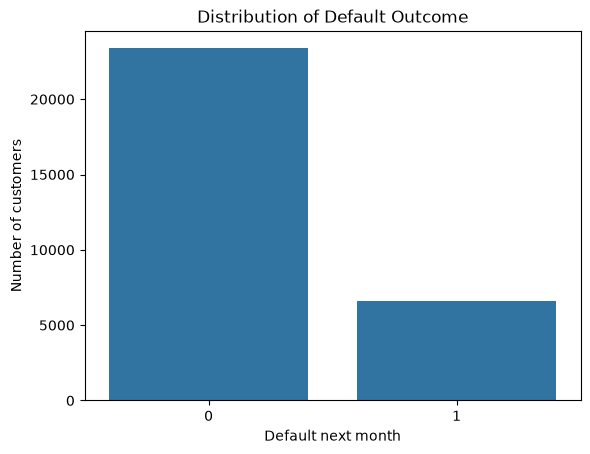

In [3]:
sns.countplot(data=df, x="default")

plt.title("Distribution of Default Outcome")
plt.xlabel("Default next month")
plt.ylabel("Number of customers")
plt.show()

In [4]:
sex_summary = (
    df.groupby("SEX")["default"]
      .agg(["count", "sum", "mean"])
)

sex_summary["default_rate_pct"] = sex_summary["mean"] * 100

sex_summary

,count,sum,mean,default_rate_pct
SEX,,,,
1,11888,2873,0.241672,24.167227
2,18112,3763,0.207763,20.776281


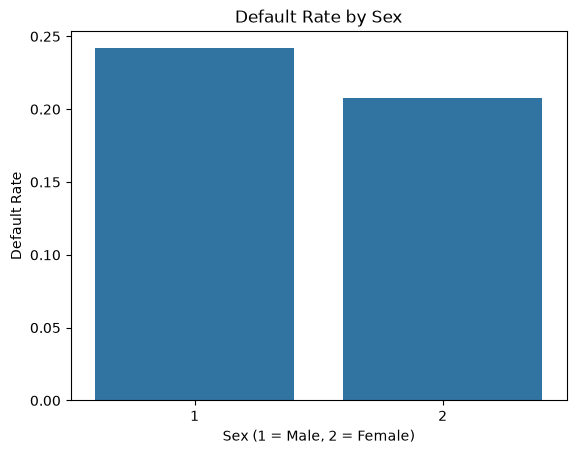

In [5]:
sns.barplot(
    data=df,
    x="SEX",
    y="default",
    errorbar=None
)

plt.title("Default Rate by Sex")
plt.xlabel("Sex (1 = Male, 2 = Female)")
plt.ylabel("Default Rate")
plt.show()

In [6]:
df["AGE"].describe()

count    30000.000000
mean        35.485500
std          9.217904
min         21.000000
25%         28.000000
50%         34.000000
75%         41.000000
max         79.000000
Name: AGE, dtype: float64

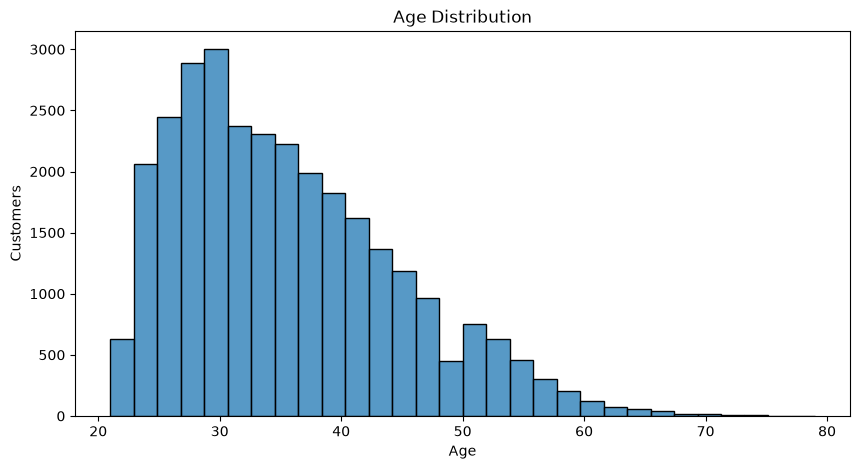

In [7]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="AGE",
    bins=30
)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Customers")
plt.show()

Grouping Age

In [8]:
age_bins = [20, 30, 40, 50, 60, 100]
age_labels = ["21-30", "31-40", "41-50", "51-60", "61+"]

df["AGE_GROUP"] = pd.cut(
    df["AGE"],
    bins=age_bins,
    labels=age_labels,
    right=True
)

df["AGE_GROUP"].value_counts().sort_index()

AGE_GROUP
21-30    11013
31-40    10713
41-50     6005
51-60     1997
61+        272
Name: count, dtype: int64

In [9]:
age_summary = (
    df.groupby("AGE_GROUP", observed=False)["default"]
      .agg(["count", "sum", "mean"])
)

age_summary["default_rate_pct"] = age_summary["mean"] * 100

age_summary

,count,sum,mean,default_rate_pct
AGE_GROUP,,,,
21-30,11013,2471,0.224371,22.437120
31-40,10713,2189,0.204331,20.433119
41-50,6005,1399,0.232973,23.297252
51-60,1997,504,0.252379,25.237857
61+,272,73,0.268382,26.838235


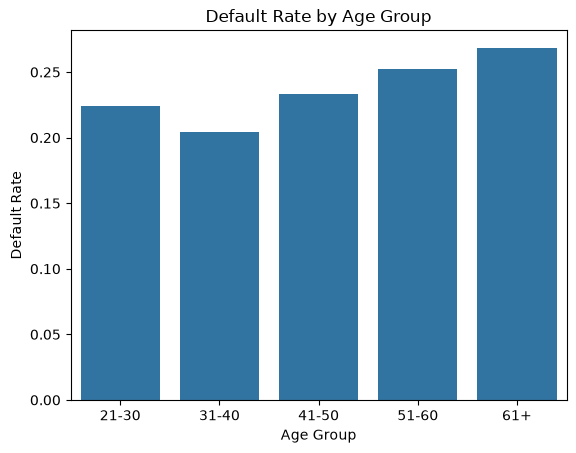

In [10]:
sns.barplot(
    data=df,
    x="AGE_GROUP",
    y="default",
    errorbar=None
)

plt.title("Default Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Default Rate")
plt.show()

Education and marriage

In [11]:
education_summary = (
    df.groupby("EDUCATION")["default"]
      .agg(["count", "sum", "mean"])
)

education_summary["default_rate_pct"] = education_summary["mean"] * 100
education_summary

,count,sum,mean,default_rate_pct
EDUCATION,,,,
1,10585,2036,0.192348,19.234766
2,14030,3330,0.237349,23.734854
3,4917,1237,0.251576,25.157616
4,468,33,0.070513,7.051282


In [12]:
marriage_summary = (
    df.groupby("MARRIAGE")["default"]
      .agg(["count", "sum", "mean"])
)

marriage_summary["default_rate_pct"] = marriage_summary["mean"] * 100
marriage_summary

,count,sum,mean,default_rate_pct
MARRIAGE,,,,
1,13659,3206,0.234717,23.471704
2,15964,3341,0.209283,20.928339
3,377,89,0.236074,23.607427


Credit limit

In [13]:
df["LIMIT_BAL"].describe()

count      30000.000000
mean      167484.322667
std       129747.661567
min        10000.000000
25%        50000.000000
50%       140000.000000
75%       240000.000000
max      1000000.000000
Name: LIMIT_BAL, dtype: float64

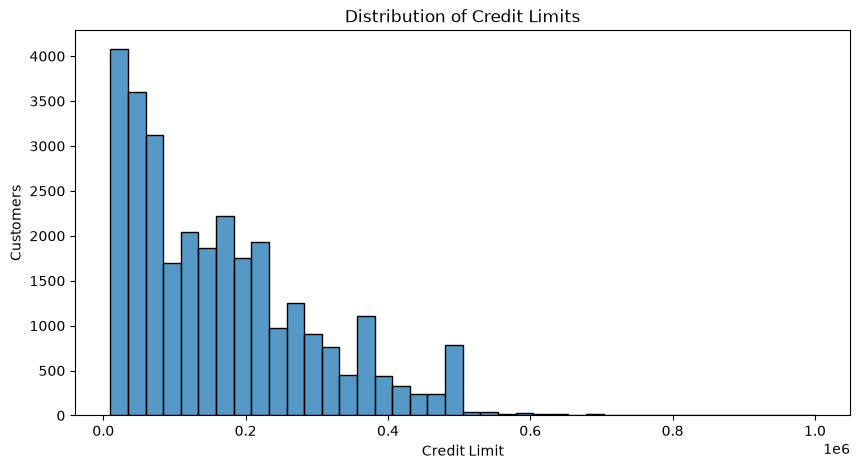

In [14]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="LIMIT_BAL",
    bins=40
)

plt.title("Distribution of Credit Limits")
plt.xlabel("Credit Limit")
plt.ylabel("Customers")
plt.show()

In [15]:
df.groupby("default")["LIMIT_BAL"].agg(
    ["count", "mean", "median", "std"]
)

,count,mean,median,std
default,,,,
0,23364,178099.726074,150000.0,131628.359660
1,6636,130109.656420,90000.0,115378.540571


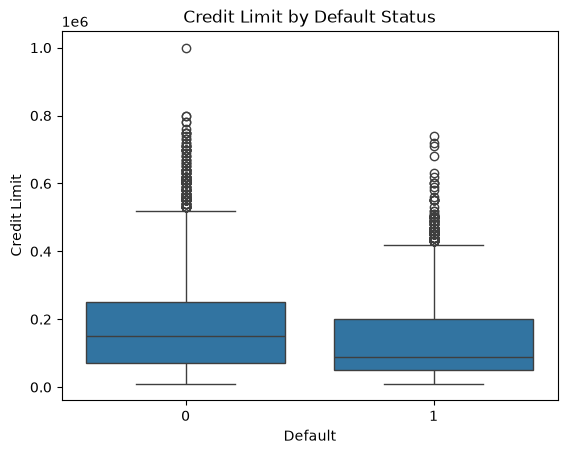

In [16]:
sns.boxplot(
    data=df,
    x="default",
    y="LIMIT_BAL"
)

plt.title("Credit Limit by Default Status")
plt.xlabel("Default")
plt.ylabel("Credit Limit")
plt.show()

Repayment status(PAY_0)

In [17]:
pay0_summary = (
    df.groupby("PAY_0")["default"]
      .agg(["count", "sum", "mean"])
)

pay0_summary["default_rate_pct"] = pay0_summary["mean"] * 100

pay0_summary

,count,sum,mean,default_rate_pct
PAY_0,,,,
-2,2759,365,0.132294,13.229431
-1,5686,954,0.167781,16.778051
0,14737,1888,0.128113,12.811291
1,3688,1252,0.339479,33.947939
2,2667,1844,0.691414,69.141357
3,322,244,0.757764,75.776398
4,76,52,0.684211,68.421053
5,26,13,0.500000,50.000000
6,11,6,0.545455,54.545455


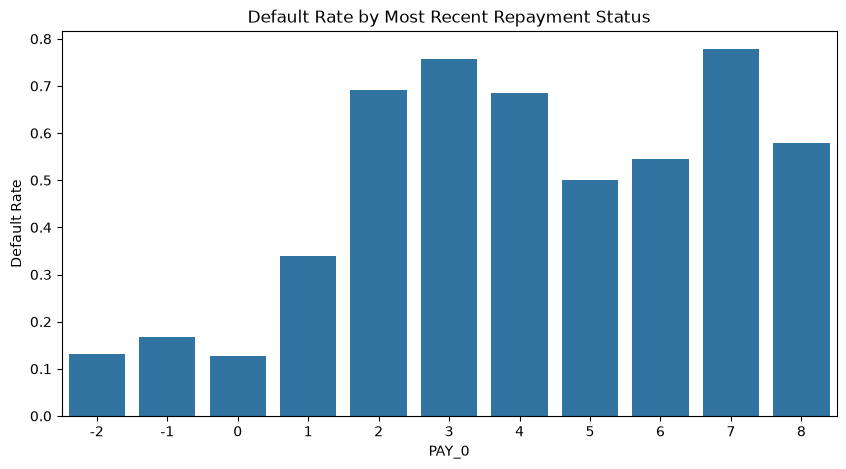

In [18]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="PAY_0",
    y="default",
    errorbar=None
)

plt.title("Default Rate by Most Recent Repayment Status")
plt.xlabel("PAY_0")
plt.ylabel("Default Rate")
plt.show()